# Simulating the BER and FER Performance of a Decoder and Their Confidence Intervals

This code is provided as supplementary material of the lecture Channel Coding - Graph-based Codes.

This code illustrates
* Carrying out FER and BER Simulations
* Calculating and Displaying Confidence Intervalks

In [23]:
import numpy as np
import sympy as sp
import shutil
from tqdm.notebook import tqdm
from scipy.stats import norm


import matplotlib
import matplotlib.pyplot as plt

# plotting options 
font = {'size'   : 16}
plt.rc('font', **font)
plt.rc('text', usetex=True if shutil.which('latex') else False)

matplotlib.rc('figure', figsize=(18, 6) )

In [24]:
# define Q function and its inverse
Q    = lambda x: norm.sf(x)    # Q(x) = 1 - Φ(x)
Qinv = lambda p: norm.isf(p)   # inverse Q function

Specify the code via its parameters $k$ and $n$. With the toggle `code_type`, we can choose between two kinds of codes of the same size:
* `'linear'`: a random systematic linear code, specified by its generator matrix $\boldsymbol{G}=[\boldsymbol{I}_k\,|\,\boldsymbol{P}]$ with a random binary $k\times(n-k)$ parity part $\boldsymbol{P}$. The codewords are obtained as $\boldsymbol{x}=\boldsymbol{u}\boldsymbol{G}$ (modulo 2) for all $2^k$ information words $\boldsymbol{u}$.
* `'random'`: a random (in general non-linear) code, whose $2^k$ codewords of length $n$ are each drawn uniformly at random from all $2^n$ binary words (i.e., all $2^k\cdot n$ bits are independent and uniform). Duplicate codewords are possible.

In [ ]:
# specify parameters of the code
k = 6
n = 12

# select the type of code:
#   'linear' -> random systematic linear code with generator matrix G = [I | P]
#   'random' -> random (generally non-linear) code with 2^k random codewords of length n (duplicates possible)
code_type = 'linear'

if code_type == 'linear':
    # random systematic generator matrix G = [I | P] with random parity part P
    G = np.hstack((np.eye(k, dtype=int), np.random.randint(0, 2, size=(k, n - k))))

    # generate table of all codewords
    # GF(2) operations are obtained by calculating modulo-2
    u = np.array([[(i >> (k - 1 - bit)) & 1 for bit in range(k)] for i in range(2**k)]) # create array of all possible information words
    code = (u @ G) % 2
elif code_type == 'random':
    # each of the 2^k codewords is drawn uniformly at random from {0,1}^n (duplicates are possible)
    code = np.random.randint(0, 2, size=(2**k, n))
else:
    raise ValueError("code_type must be 'linear' or 'random'")


Construct table with codewords.

In [34]:
# codebook modulated to BPSK symbols, note that (-1)^x = 1 - 2*x for x in {0, 1}
code_bpsk = 1 - 2*code

### ML Decoder for the BI-AWGN Channel

We transmit over the binary-input AWGN (BI-AWGN) channel. The bits of a codeword $\boldsymbol{x}\in\mathcal{C}$ are mapped to BPSK symbols via $0\to+1$ and $1\to-1$, i.e., the channel input is $(-1)^{x_t}=1-2x_t$ (in the code this is `code_bpsk = 1 - 2*code`). The channel output is
$$y_t = (-1)^{x_t} + n_t,\qquad n_t\sim\mathcal{N}(0,\sigma_n^2),\qquad \sigma_n^2=\frac{1}{2E_s/N_0},$$
where the symbol energy is normalized to $E_s=1$.

The maximum-likelihood (ML) decoder selects the codeword $\hat{\boldsymbol{x}}$ that maximizes the likelihood of the received vector $\boldsymbol{y}$. As the channel is memoryless and the noise is Gaussian, we have
$$
\hat{\boldsymbol{x}}
=\arg\max_{\boldsymbol{x}^{[i]}\in\mathcal{C}}\sum_{t=1}^{n}\ln f_{Y|X}\big(y_t|x_t^{[i]}\big)
=\arg\max_{\boldsymbol{x}^{[i]}\in\mathcal{C}}\sum_{t=1}^{n}\left(\ln\frac{1}{\sqrt{2\pi}\sigma_n}-\frac{\big(y_t-(-1)^{x_t^{[i]}}\big)^2}{2\sigma_n^2}\right)
=\arg\max_{\boldsymbol{x}^{[i]}\in\mathcal{C}}\sum_{t=1}^{n}-\big(y_t-(-1)^{x_t^{[i]}}\big)^2 ,
$$
where the constant term and the positive factor $1/(2\sigma_n^2)$ do not change the maximization. Expanding the square gives $y_t^2+1-2y_t(-1)^{x_t^{[i]}}$. Since $y_t^2+1$ is the same for all codewords, it can also be dropped, which yields the **correlation decoder**
$$
\hat{\boldsymbol{x}}=\arg\max_{\boldsymbol{x}^{[i]}\in\mathcal{C}}\sum_{t=1}^{n}y_t\,(-1)^{x_t^{[i]}} .
$$

Equivalently, ML decoding on the BI-AWGN channel is a minimum Euclidean distance decoder. In the simulation below, we compute the correlation of $\boldsymbol{y}$ with all $2^k$ BPSK-modulated codewords (`np.sum(code_bpsk * y, 1)`) and pick the codeword with the largest value (`np.argmax`).

In [42]:
# BI-AWGN channel
esno_dB_range = np.arange(-3, 7, 0.5) # specify Es/N0 in dB

esno_lin_range = 10**(esno_dB_range/10)

## Background: FER and BER Simulations and Their Confidence Intervals

We estimate the performance of the ML decoder by a **Monte-Carlo simulation**: we transmit $N$ codewords $\boldsymbol{x}_1,\ldots,\boldsymbol{x}_N$ drawn at random from the code $\mathcal{C}$ (`transmit_idx`), decode them to $\hat{\boldsymbol{x}}_1,\ldots,\hat{\boldsymbol{x}}_N$ (`ML_decision_idx`) and count the errors. As each simulated estimate is itself random, we also need to know **how confident we can be** in it. This is quantified by confidence intervals.

### Frame error rate (FER)

The FER approximates the codeword error probability $P_\mathrm{e}=P(\hat{\boldsymbol{X}}\neq\boldsymbol{x})$:
$$
P_\mathrm{e}=\mathbb{E}\{\mathbb{1}_{\{\hat{\boldsymbol{X}}\neq\boldsymbol{x}\}}\}\;\overset{N\text{ large}}{\approx}\;\frac{1}{N}\sum_{t=1}^{N}\mathbb{1}_{\{\hat{\boldsymbol{x}}_t\neq\boldsymbol{x}_t\}}=:\hat{P}_\mathrm{e}
=\frac{\text{number of erroneous codewords}}{\text{number of simulated codewords}}=\frac{N_\mathrm{e}}{N}
$$
In the code, `N_e` counts the erroneous codewords and `FER_estimate = N_e / N`.

**Confidence interval.** Let $E_i=\mathbb{1}_{\{\hat{\boldsymbol{X}}_i\neq\boldsymbol{x}_i\}}$. Each $E_i$ is a Bernoulli random variable with mean $P_\mathrm{e}$ and variance $P_\mathrm{e}(1-P_\mathrm{e})$, and $\hat{P}_\mathrm{e}=\frac1N\sum_i E_i$. By the central limit theorem, for large enough $N$, $\hat{P}_\mathrm{e}\sim\mathcal{N}(\mu_{\hat P_\mathrm{e}},\sigma^2_{\hat P_\mathrm{e}})$ with
$$
\mu_{\hat P_\mathrm{e}}=P_\mathrm{e}\approx \hat P_\mathrm{e},\qquad \sigma^2_{\hat P_\mathrm{e}}=\frac{1}{N}P_\mathrm{e}(1-P_\mathrm{e})\approx\frac{1}{N}\hat{P}_\mathrm{e}(1-\hat{P}_\mathrm{e}),
$$
where the unknown $P_\mathrm{e}$ is replaced by its estimate. We want the $\beta$-confidence interval $P(\hat{P}_\mathrm{e}-a<P_\mathrm{e}\le\hat{P}_\mathrm{e}+a)\overset{!}{=}\beta$. With $Q(x):=P(Z>x)$ for $Z\sim\mathcal{N}(0,1)$ this means $1-2Q\big(a/\sigma_{\hat P_\mathrm{e}}\big)=\beta$, and solving for $a$ gives
$$
a=\sigma_{\hat P_\mathrm{e}}\,Q^{-1}\!\left(\frac{1-\beta}{2}\right)\approx Q^{-1}\!\left(\frac{1-\beta}{2}\right)\sqrt{\frac{\hat{P}_\mathrm{e}(1-\hat{P}_\mathrm{e})}{N}}
$$

In the code, `Qinv((1 - beta) / 2)` is $Q^{-1}\big(\frac{1-\beta}{2}\big)$, and `a = Qinv((1 - beta) / 2) * np.sqrt(N_e * (N - N_e) / N**3)` is the same as the formula above, since $\hat{P}_\mathrm{e}(1-\hat{P}_\mathrm{e})/N=N_\mathrm{e}(N-N_\mathrm{e})/N^3$. The interval is $[\hat{P}_\mathrm{e}-a,\;\hat{P}_\mathrm{e}+a]$ (`FER_confidence_interval`).

**Rules of thumb** (for $\beta=0.95$, see [Ham15]). Let $N_\mathrm{e}$ be the number of observed codeword errors.
1. An error-free simulation ($N_\mathrm{e}=0$) of $N$ codewords certifies that $P_\mathrm{e}<4/N$.
2. At least $N_\mathrm{e}=4$ codeword errors must be observed to determine $P_\mathrm{e}$ within an order of magnitude.
3. $\hat{P}_\mathrm{e}$ is accurate within $\pm100\gamma\,\%$ if $N_\mathrm{e}=4/\gamma^2$ codeword errors are observed (e.g., $N_\mathrm{e}=16$ for $\pm50\,\%$, $N_\mathrm{e}=400$ for $\pm10\,\%$).
4. Aborting a simulation right after the first codeword error gives a biased estimate $\hat{P}_\mathrm{e}$. The bias can exceed an order of magnitude if $P_\mathrm{e}<10^{-6}$.

### Bit error rate (BER)

The BER approximates the error probability of a single code bit, $P_\mathrm{b}=P(\hat{X}_i\neq x_i)$, and is usually computed as
$$
\hat{P}_\mathrm{b}=\frac{\text{number of erroneous bits}}{\text{number of simulated bits}}=\frac{1}{nN}\sum_{t=1}^{N}B_t,
$$
where $B_t$ is the number of bit errors in codeword $\boldsymbol{x}_t$. In the code, `B_i` is the number of positions in which the decoded and the transmitted codeword differ, `B_i_sum` $=\sum_t B_t$ and `BER_estimate = B_i_sum / (N * n)`. Note that the bit errors within one codeword are in general **not independent** (an ML decoding error flips several bits at once), so we treat the whole codeword as one trial and look at the random variable $B_i\in\{0,\ldots,n\}$.

**Confidence interval.** Let $\mu:=\mathbb{E}\{B_i\}$ and $\sigma^2:=\mathrm{Var}\{B_i\}=\mathbb{E}\{B_i^2\}-\mu^2$. As for the FER, the central limit theorem gives $\hat{P}_\mathrm{b}\sim\mathcal{N}(\mu_{\hat P_\mathrm{b}},\sigma^2_{\hat P_\mathrm{b}})$ for large $N$ with
$$
\mu_{\hat P_\mathrm{b}}=\frac{\mu}{n}=P_\mathrm{b},\qquad
\sigma^2_{\hat P_\mathrm{b}}=\frac{\sigma^2}{n^2N}=\frac{1}{n^2N}\big(\mathbb{E}\{B_i^2\}-\mu^2\big).
$$
The first and second moments are estimated from the simulation,
$$
\hat\mu=\frac1N\sum_{i=1}^{N}B_i=n\hat{P}_\mathrm{b},\qquad
\hat\sigma^2=\left(\frac1N\sum_{i=1}^{N}B_i^2\right)-\hat\mu^2 ,
$$
which is why the code accumulates `B_i_sum` $=\sum_i B_i$ and `B_i_squared_sum` $=\sum_i B_i^2$. The $\beta$-confidence interval $[\hat{P}_\mathrm{b}-\tilde a,\;\hat{P}_\mathrm{b}+\tilde a]$ (`BER_confidence_interval`) is then given by
$$
\tilde a=\frac{\hat\sigma}{n\sqrt{N}}\,Q^{-1}\!\left(\frac{1-\beta}{2}\right)
=\frac{1}{n\sqrt{N}}\sqrt{\left(\frac1N\sum_{i=1}^{N}B_i^2\right)-\left(\frac1N\sum_{i=1}^{N}B_i\right)^2}\cdot Q^{-1}\!\left(\frac{1-\beta}{2}\right),
$$
which corresponds to the line `a_tilde = Qinv((1 - beta) / 2) * np.sqrt(B_i_squared_sum / N - (B_i_sum / N)**2) / np.sqrt(n * N)`.

**Accuracy criterion.** The error of the BER estimate, with $\beta$-confidence, is less than $100\gamma\,\%$ of the observed BER $\hat{P}_\mathrm{b}$ if
$$
\tilde B:=\frac{\left(\sum_{i=1}^{N}B_i\right)^2}{\sum_{i=1}^{N}B_i^2}>\left(\frac1\gamma\,Q^{-1}\!\left(\frac{1-\beta}{2}\right)\right)^2 .
$$
In the code, $\tilde B$ is `B_i_sum**2 / B_i_squared_sum`. The main idea of the (omitted) proof is to drop the term $\big(\frac1N\sum_i B_i\big)^2\ge0$ under the square root, which gives an upper bound on $\tilde a$ that is smaller than $\gamma\hat{P}_\mathrm{b}$ if the above condition holds.

**Rule of thumb.** With 95 % confidence, the BER is within $\pm10\,\%$ of the simulated BER when $\tilde B>385$. More generally, the minimum $N_\mathrm{e}$ (FER) or $\tilde B$ (BER) needed to reach a given accuracy at confidence $\beta$ is [Ham15, Tab. 3]:

| Error in FER or BER | $\beta=0.9$ | $\beta=0.95$ | $\beta=0.99$ |
|---|---:|---:|---:|
| 1 % | 27056 | 38415 | 66349 |
| 2.5 % | 4329 | 6147 | 10616 |
| 5 % | 1083 | 1537 | 2654 |
| 10 % | 271 | 385 | 664 |
| 25 % | 44 | 62 | 107 |
| 50 % | 11 | 16 | 27 |

### Remarks on the implementation

* Both intervals rely on the normal approximation from the central limit theorem. It is only reliable if enough errors are observed (see the rules of thumb). With few or no errors, the lower bound can become negative, which is meaningless for an error rate. The code therefore clips the lower bounds at $0$.
* To get a reliable estimate at high SNR, $N$ has to be increased until the required number of errors ($N_\mathrm{e}$ or $\tilde B$) is observed.

### Reference

[Ham15] J. Hamkins, "Confidence intervals for error rates observed in coded communications systems," *IPN Progress Report*, vol. 42-201, pp. 1-17, May 2015, available online at <https://ipnpr.jpl.nasa.gov/progress_report/42-201/201C.pdf>

In [ ]:
# calculate Monte-Carlo-Estimate of ML performance
# transmit N codewords
N = 100000

# confidence level for confidence intervals
beta = 0.95

FER_estimate = np.zeros(len(esno_lin_range))
FER_confidence_interval = np.zeros((len(esno_lin_range), 2))

BER_estimate = np.zeros(len(esno_lin_range))
BER_confidence_interval = np.zeros((len(esno_lin_range), 2))


for esno_idx, esno_lin in enumerate(tqdm(esno_lin_range)):
    # standard deviation of noise distribution
    sigma_n = np.sqrt(1 /(2*esno_lin))

    # select random codewords to be transmitted for this SNR valuer
    transmit_idx = np.random.randint(0, code.shape[0], size=N)

    # number of frame errors
    N_e = 0
    # sums needed to compute the bit error rate and its confidence interval
    B_i_sum = 0
    B_i_squared_sum = 0

    for j in range(N):
        x = code_bpsk[transmit_idx[j], :]
                
        # simulate transmission over BI-AWGN channel
        y = x + sigma_n * np.random.randn(x.shape[0])
        
        # calculate correlation with all codewords (ML Decoder)
        correlation = np.sum(code_bpsk * y, 1)        
        ML_decision_idx = np.argmax(correlation)

        # in case we make a decoding error
        if int(ML_decision_idx != transmit_idx[j]):
            N_e = N_e + 1
            # number of bit positions in which the estimated codeword differs from the transmitted one
            B_i = int(np.sum(code[ML_decision_idx, :] != code[transmit_idx[j], :]))
            B_i_sum = B_i_sum + B_i
            B_i_squared_sum = B_i_squared_sum + B_i**2

    FER_estimate[esno_idx] = N_e / N
    BER_estimate[esno_idx] = B_i_sum / (N * n)

    # calculate FER confidence interval
    a = Qinv((1 - beta) / 2) * np.sqrt(N_e * (N - N_e) / N**3)
    FER_confidence_interval[esno_idx, 0] = FER_estimate[esno_idx] - a
    FER_confidence_interval[esno_idx, 1] = FER_estimate[esno_idx] + a

    # calculate BER confidence interval
    a_tilde = Qinv((1 - beta) / 2) * np.sqrt((B_i_squared_sum / N - (B_i_sum / N)**2)) / np.sqrt(n*N)
    BER_confidence_interval[esno_idx, 0] = BER_estimate[esno_idx] - a_tilde
    BER_confidence_interval[esno_idx, 1] = BER_estimate[esno_idx] + a_tilde

    #print(f"Es/N0 = {esno_dB_range[esno_idx]:.1f} dB: Btilde = {(B_i_sum**2)/(B_i_squared_sum):.4f}")
# the normal approximation can yield negative lower bounds, which are meaningless for error rates: clip at 0
FER_confidence_interval = np.maximum(FER_confidence_interval, 0)
BER_confidence_interval = np.maximum(BER_confidence_interval, 0)
assert np.all(FER_confidence_interval >= 0) and np.all(BER_confidence_interval >= 0)

  0%|          | 0/20 [00:00<?, ?it/s]

### Plotting and Saving the Results

The next cell visualizes the simulation results:

* **Curves:** the estimated BER (`BER_estimate`, solid line) and FER (`FER_estimate`, dashed line) are plotted over $E_s/N_0$ in dB (`esno_dB_range`). A logarithmic $y$-axis (`ax.semilogy`) is used, as error rates typically span several orders of magnitude.
* **Confidence intervals:** the $\beta$-confidence intervals (`BER_confidence_interval`, `FER_confidence_interval`) are drawn as shaded bands around the respective curves (`ax.fill_between`, lower bound in column 0, upper bound in column 1). The true error rate lies within the band with probability $\beta$ (95 % by default). Narrow bands indicate a reliable estimate, whereas wide bands indicate that too few errors were observed and $N$ should be increased.
* **Zero values:** a rate of exactly $0$ (no error observed) or a lower bound clipped to $0$ cannot be shown on a logarithmic axis, so curves or bands may end or be cut off at high SNR.

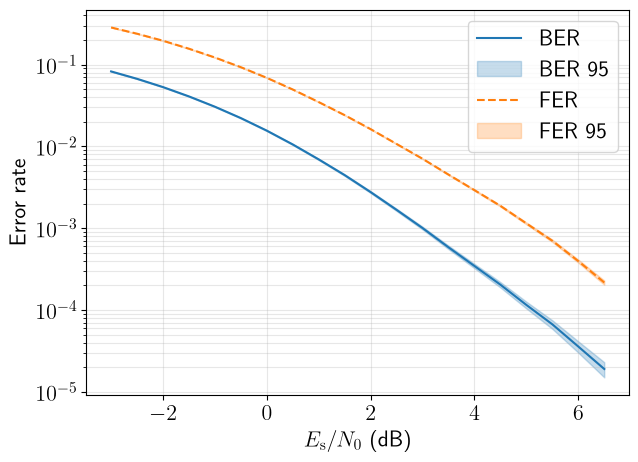

In [ ]:
import matplotlib.pyplot as plt

# set to True to save the results to a csv file, False to skip saving
save_csv = False

fig, ax = plt.subplots(figsize=(7, 5))

# BER: solid line, FER: dashed line, shaded areas show the confidence intervals
ax.semilogy(esno_dB_range, BER_estimate, '-', color='C0', label='BER')
ax.fill_between(esno_dB_range, BER_confidence_interval[:, 0], BER_confidence_interval[:, 1],
                color='C0', alpha=0.25, label=f'BER {beta:.0%} confidence interval')

ax.semilogy(esno_dB_range, FER_estimate, '--', color='C1', label='FER')
ax.fill_between(esno_dB_range, FER_confidence_interval[:, 0], FER_confidence_interval[:, 1],
                color='C1', alpha=0.25, label=f'FER {beta:.0%} confidence interval')

ax.set_xlabel(r'$E_{\mathrm{s}}/N_0$ (dB)')
ax.set_ylabel('Error rate')
ax.grid(True, which='both', alpha=0.3)
ax.legend()
plt.show()

# save results to a csv file (first line is a descriptor of the columns)
if save_csv:
    results = np.column_stack((esno_dB_range, FER_estimate, BER_estimate,
                               FER_confidence_interval, BER_confidence_interval))
    header = 'esno_dB,fer,ber,fer_ci_lower,fer_ci_upper,ber_ci_lower,ber_ci_upper'
    filename = f'BER_FER_results_n{n}_k{k}_N{N}.csv'
    np.savetxt(filename, results, delimiter=',', header=header, comments='')